# Structure Factor Analysis with Radius Parameter

Analysis of binary polymer simulations with nanoparticle packing, including nanoparticle radius as a variable.

## Parameters
- **NP_frac**: [0.5, 0.64]
- **RAD**: [3.75, 5]
- **POT**: [10.0, 13.75, 17.5, 21.25, 25.0]
- **Nb**: [5, 10, 20]
- **rep**: [0, 1, 2]

In [1]:
# Cell 1: Imports
import numpy as np
import matplotlib.pyplot as plt
import math
import os
import pandas as pd
import glob
import subprocess
import re
from matplotlib.ticker import MultipleLocator
import matplotlib
import seaborn as sns
from scipy.optimize import curve_fit
from multiprocessing import Pool

# Set plotting style
plt.rc('font', family='serif')

In [2]:
# Cell 2: Helper Functions

def search_files(directory):
    """Recursively search for files within subdirectories"""
    file_list = []
    for root, dirs, files in os.walk(directory):
        for file in files:
            file_list.append(os.path.join(root, file))
    return file_list

def calculate_log_steps(max_steps, n_frames, freq):
    """Calculate logarithmically spaced timesteps"""
    steps = []
    mult_factor = (max_steps / freq) ** (1 / (n_frames))
    for i in range(n_frames):
        freq = freq * mult_factor
        steps.append(int(freq))
    return steps

In [11]:
# Cell 3: Parallel Structure Factor Extraction

# Directory where the density files are located
#file_directory = "/home/gabriel/Projects/Static_NP_Confined_Phase_Separation/Results/Density"
#file_directory = "/home/gabriel/Projects/Neutral_Equilibrated_NP_Confined_PS/Results/Density"
file_directory = "/home/gabriel/Projects/Asymmetric_Equilibrated_NP_Confined_PS/Results/Density"


# Executable command to run
executable_command = "/home/gabriel/MATILDA.FT/utils/post-proc/calc-sk/calc-sk-per-frame"

# Process file function
def process_file(file_path):
    filename = os.path.basename(file_path)
    dirname = os.path.dirname(file_path)
    
    # Updated pattern to include RAD parameter
    #pattern = re.compile(   
    #    r"PS_in_NP_frac_(0\.36|0\.5|0\.64)_RAD_(3\.75|7\.5)_POT_(10\.0|13\.75|17\.5|21\.25|25\.0)_Nb_(10|20|30)_rep_(0|1|2)_den\.bin$"
    #)
    pattern = re.compile(   
    r"PS_in_NP_frac_0.5_rad_5.0_POT_(10\.0|13\.75|17\.5|21\.25|25\.0)_Nb_(10|20|30)_rep_(0|1|2)_densities.bin$"
    )
    
    if pattern.match(filename):
        os.chdir(dirname)
        print(f"Starting: {filename}")
        
        # Run calc-sk-per-frame
        command = [executable_command, filename, "0", "1"]
        subprocess.run(command, check=True)
        return f"Finished: {filename}"

# Find all files
files = search_files(file_directory)

# Process files in parallel (4 workers)
with Pool(processes=4) as pool:
    results = pool.map(process_file, files)

Starting: PS_in_NP_frac_0.5_rad_5.0_POT_13.75_Nb_10_rep_1_densities.binStarting: PS_in_NP_frac_0.5_rad_5.0_POT_13.75_Nb_10_rep_2_densities.bin
Starting: PS_in_NP_frac_0.5_rad_5.0_POT_13.75_Nb_10_rep_0_densities.bin
Starting: PS_in_NP_frac_0.5_rad_5.0_POT_25.0_Nb_10_rep_0_densities.bin

Dim = 3
Nx[0]: 81 Nx[1]: 81 Nx[2]: 81
ntypes: 3
Dim = 3
Nx[0]: 81 Nx[1]: 81 Nx[2]: 81
ntypes: 3
Dim = 3
Nx[0]: 81 Nx[1]: 81 Nx[2]: 81
ntypes: 3
Dim = 3
Nx[0]: 81 Nx[1]: 81 Nx[2]: 81
ntypes: 3
fft initialized!
M: 531441 ML: 531441
fft initialized!
M: 531441 ML: 531441
fft initialized!
M: 531441 ML: 531441
fft initialized!
M: 531441 ML: 531441
Starting: PS_in_NP_frac_0.5_rad_5.0_POT_25.0_Nb_10_rep_2_densities.bin
Starting: PS_in_NP_frac_0.5_rad_5.0_POT_25.0_Nb_10_rep_1_densities.bin
Successfully read 33 frames
Successfully read 33 frames
Starting: PS_in_NP_frac_0.5_rad_5.0_POT_21.25_Nb_10_rep_0_densities.bin
Successfully read 33 frames
Dim = 3
Nx[0]: 81 Nx[1]: 81 Nx[2]: 81
ntypes: 3
Dim = 3
Nx[0]: 81 Nx[1]

In [12]:
# Cell 4: Calculate logarithmic timesteps

max_steps = 2000001
n_frames = 33
freq = 1000

steps = calculate_log_steps(max_steps, n_frames, freq)
print("Logarithmic timesteps:")
print(steps)

Logarithmic timesteps:
[1259, 1585, 1995, 2512, 3163, 3982, 5014, 6313, 7948, 10007, 12599, 15862, 19971, 25144, 31656, 39856, 50180, 63177, 79541, 100143, 126082, 158740, 199856, 251622, 316796, 398851, 502160, 632228, 795985, 1002158, 1261733, 1588543, 2000000]


In [13]:
# Cell 5: Load and Process Structure Factor Data
#file_directory = "/home/gabriel/Projects/Neutral_Equilibrated_NP_Confined_PS/Results/Density"
file_directory = "/home/gabriel/Projects/Asymmetric_Equilibrated_NP_Confined_PS/Results/Density"

# Find new structure factor files
new_files = search_files(file_directory)

# Empty list for storing dataframes
df_list = []

for filepath in new_files:
    filename = os.path.basename(filepath)
    
    # Updated pattern to capture RAD parameter and frame number
    pattern = re.compile(
        r"PS_in_NP_frac_0.5_rad_5.0_POT_(10\.0|13\.75|17\.5|21\.25|25\.0)_Nb_(10|20|30)_rep_(0|1|2)_densities_type_1_frame_(\d+)\.sk"

    )
    
    if pattern.match(filename):
        # Read data from file (columns: k and structure_factor)
        file_data = pd.read_csv(
            filepath,
            usecols=[3, 4],
            delim_whitespace=True,
            header=None,
            names=["structure_factor", "k"],
            index_col=False,
            dtype={"structure_factor": np.float16, "k": np.float16}
        )
        
        # Parse parameters from filename
        file_data["phi_np"] = re.findall(r'frac_(0\.\d+)', filename)[0]
        file_data["rad"] = re.findall(r'rad_(\d+\.\d+)', filename)[0]
        file_data["POT"] = re.findall(r'POT_(\d+\.\d+)', filename)[0]
        file_data["Nb"] = re.findall(r'Nb_(\d+)', filename)[0]
        file_data["rep"] = re.findall(r'rep_(\d+)', filename)[0]
        
        frame = int(re.findall(r'frame_(\d+)', filename)[0])
        file_data["frame"] = frame
        file_data["step"] = steps[np.int8(frame)]
        
        # Filter data for k <= 2.0
        file_data = file_data[file_data["k"] <= 2.0]
        
        # Append to list
        df_list.append(file_data)

# Concatenate all DataFrames
data = pd.concat(df_list, ignore_index=True)

# Free memory
del df_list

print(f"Loaded {len(data)} data points")
print(f"\nData columns: {data.columns.tolist()}")
print(f"\nUnique values:")
print(f"  phi_np: {sorted(data['phi_np'].unique())}")
print(f"  POT: {sorted(data['POT'].unique())}")
print(f"  rep: {sorted(data['rep'].unique())}")

Loaded 9676260 data points

Data columns: ['structure_factor', 'k', 'phi_np', 'rad', 'POT', 'Nb', 'rep', 'frame', 'step']

Unique values:
  phi_np: ['0.5']
  POT: ['10.0', '13.75', '17.5', '21.25', '25.0']
  rep: ['0', '1', '2']


In [ ]:
# Cell 6: Plot S(q) vs q with Radius Parameter

# Select potentials and frames of interest
potentials_of_interest = ['10.0', '13.75', '17.5', '21.25' '25.0']
frames_of_interest = [10, 20, 30]

# Filter data
filtered_data = data[
    (data['POT'].isin(potentials_of_interest)) &
    (data['frame'].isin(frames_of_interest))
].copy()

# Group by phi_np, POT, and Nb (will show multiple radius values on same plot)
grouped_data = filtered_data.groupby(["phi_np", "POT", "Nb"])

# Color palette for frames (time progression)
frame_colors = sns.color_palette("viridis", len(frames_of_interest))
frame_color_map = dict(zip(frames_of_interest, frame_colors))

# Line styles for radius
radius_linestyles = {'3.75': '-', '7.5': '--'}
radius_labels = {'3.75': 'RAD=3.75', '7.5': 'RAD=7.5'}

# Plot for each group
for (phi_np, pot, nb), group_data in grouped_data:
    plt.figure(figsize=(10, 7))
    
    # Get unique radius values in this group
    radii = sorted(group_data['rad'].unique())
    
    # Plot for each frame
    for frame in frames_of_interest:
        frame_data = group_data[group_data['frame'] == frame].copy()
        
        if frame_data.empty:
            continue
        
        # Calculate time
        time_val = steps[int(frame)] * 0.005
        
        # Plot for each radius value
        for rad in radii:
            rad_data = frame_data[frame_data['rad'] == rad].copy()
            
            if rad_data.empty:
                continue
            
            # Bin the data
            rad_data = rad_data[['k', 'structure_factor']].dropna().astype(float)
            rad_data['bq'] = pd.cut(rad_data['k'], bins=100)
            binned_data = rad_data.groupby('bq', observed=True).mean()
            binned_data['bq_mid'] = [interval.mid for interval in binned_data.index]
            
            # Create label
            label_text = f"t={time_val:.1f}, {radius_labels[rad]}"
            
            # Plot
            plt.plot(
                binned_data['bq_mid'],
                binned_data['structure_factor'],
                linestyle=radius_linestyles[rad],
                color=frame_color_map[frame],
                linewidth=2,
                label=label_text
            )
    
    # Format plot
    pot_ratio = float(pot) / 10.0
    plt.title(
        rf"$\phi_{{np}}={phi_np}$, $N_b={nb}$ | Potential Ratio $\chi_{{ratio}}={pot_ratio:.1f}$",
        fontsize=18
    )
    plt.xlabel(r"$|q|$", fontsize=22)
    plt.ylabel(r"$S(q)$", fontsize=22)
    plt.xlim(0.0, 8)
    plt.xticks(np.arange(0, 8.1, 1.0), fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(fontsize=11, frameon=True, ncol=2)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [14]:
# Cell 7: Lorentzian Peak Fitting

def lorentzian(x, center, area, width, bg):
    """Lorentzian function for peak fitting"""
    return area / (1.0 + ((x - center) / width)**2) + bg

result_rows = []

# Group by all parameters including radius
grouped_data = data.groupby(["phi_np", "rad", "POT", "Nb", "rep"])

# Define minimum k
min_k = 2 * math.pi / 52.5
x_q = np.arange(0, 2.0, 0.01)

for (phi_np, rad, pot, nb, rep), group_data in grouped_data:
    # Filter for equilibration
    group_data = group_data.loc[group_data["step"] > 0]
    min_k_flag = False
    
    for timestep, frame_data in group_data.groupby("step"):
        # Focus on low-q region
        xdata = frame_data.loc[frame_data["k"] < 2.0, "k"].values
        ydata = frame_data.loc[frame_data["k"] < 2.0, "structure_factor"].values
        
        if len(xdata) < 5:
            continue
        
        # Initial parameters for fit
        initial_params = [xdata[np.argmax(ydata)], np.max(ydata), 0.1, 0]
        
        if min_k_flag:
            k_star = min_k
        else:
            try:
                params, _ = curve_fit(lorentzian, xdata, ydata, p0=initial_params)
                lorentz_fit_value = lorentzian(x_q, *params)
                k_star = x_q[lorentz_fit_value.argmax()]
            except RuntimeError:
                # Fallback to simple argmax if fit fails
                k_star = xdata[np.argmax(ydata)]
            
            # Apply constraint
            if k_star <= min_k:
                k_star = min_k
                min_k_flag = True
        
        result_rows.append([phi_np, rad, pot, nb, timestep, rep, k_star])

# Create results DataFrame
result_data = pd.DataFrame(
    result_rows,
    columns=["phi_np", "rad", "POT", "Nb", "timestep", "rep", "k_star"]
)

# Aggregate across replicates
aggregated_data = result_data.groupby(["phi_np", "rad", "POT", "Nb", "timestep"]).agg(
    k_star_mean=('k_star', 'mean'),
    k_star_std=('k_star', 'std')
).reset_index()

print(f"Fitted {len(result_data)} data points")
print(f"Aggregated to {len(aggregated_data)} unique parameter combinations")

Fitted 495 data points
Aggregated to 165 unique parameter combinations


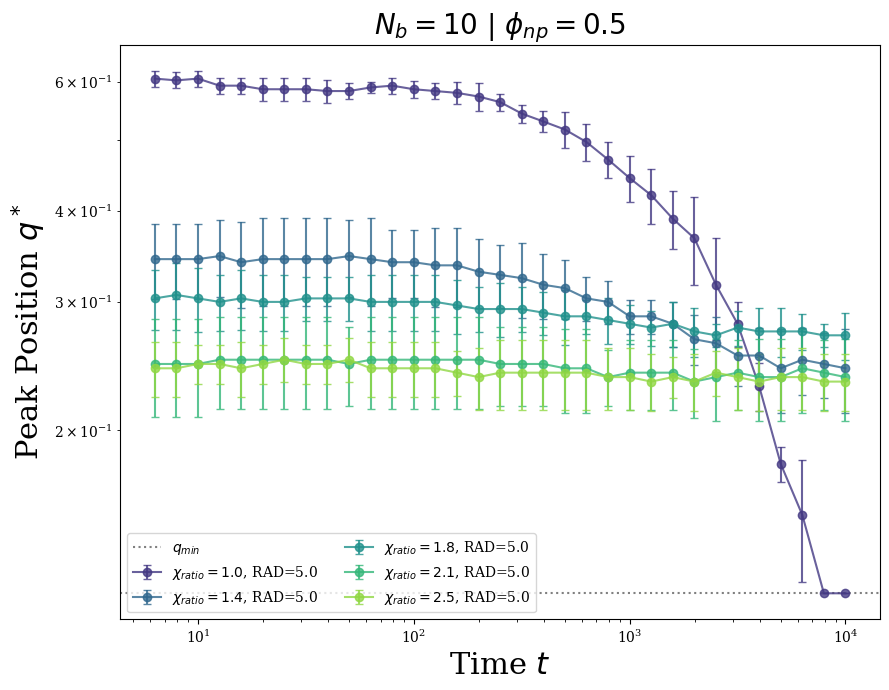

In [15]:
# Cell 8: Plot q* vs Time with Radius Parameter

unique_nbs = sorted(aggregated_data["Nb"].unique())
unique_phis = sorted(aggregated_data["phi_np"].unique())
unique_pots = sorted(aggregated_data["POT"].unique())
unique_rads = sorted(aggregated_data["rad"].unique())

# Color map for POT values
colors = sns.color_palette("viridis", len(unique_pots))
pot_color_map = dict(zip(unique_pots, colors))

# Marker styles for radius
radius_markers = {'5.0': 'o', '7.5': '^'}  # circles vs triangles
radius_labels = {'5.0': 'RAD=5.0', '7.5': 'RAD=7.5'}

# Plot for each (Nb, phi_np) combination
for nb_val in unique_nbs:
    for phi_val in unique_phis:
        # Filter data
        subset_data = aggregated_data[
            (aggregated_data["Nb"] == nb_val) &
            (aggregated_data["phi_np"] == phi_val)
        ]
        
        if subset_data.empty:
            continue
        
        plt.figure(figsize=(9, 7))
        ax = plt.gca()
        
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel(r"Time $t$", fontsize=22)
        ax.set_ylabel(r"Peak Position $q^*$", fontsize=22)
        ax.set_title(
            rf"$N_b={nb_val}$ | $\phi_{{np}}={phi_val}$",
            fontsize=20
        )
        
        # Plot for each POT and radius combination
        for pot_val in unique_pots:
            for rad_val in unique_rads:
                group = subset_data[
                    (subset_data["POT"] == pot_val) &
                    (subset_data["rad"] == rad_val)
                ].sort_values("timestep")
                
                if group.empty:
                    continue
                
                pot_ratio = float(pot_val) / 10.0
                label = rf"$\chi_{{ratio}}={pot_ratio:.1f}$, {radius_labels[rad_val]}"
                
                ax.errorbar(
                    group["timestep"] * 0.005,
                    group["k_star_mean"],
                    yerr=group["k_star_std"],
                    label=label,
                    color=pot_color_map[pot_val],
                    marker=radius_markers[rad_val],
                    linestyle='-',
                    markersize=6,
                    capsize=3,
                    alpha=0.8
                )
        
        # Add q_min reference line
        ax.axhline(min_k, color="gray", linestyle=":", label=r"$q_{min}$")
        
        ax.legend(fontsize=10, ncol=2, frameon=True)
        plt.tight_layout()
        plt.show()